In [ ]:
import torch
import torch.nn as nn
import numpy as np

In [ ]:
import json

with open('app\artifacts\vocab.json', 'r') as file:
    vocab = json.load(file)
len(vocab)

64649

In [3]:
def text_to_indices(sentence, vocab):

  numerical_sentence = []

  for token in sentence:
    if token in vocab:
      numerical_sentence.append(vocab[token])
    else:
      numerical_sentence.append(vocab['<unk>'])

  return numerical_sentence


In [4]:
class LSTMModel(nn.Module):

  def __init__(self, vocab_size):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, 100)
    self.lstm = nn.LSTM(input_size=100, hidden_size=200,batch_first=True)
    self.fc = nn.Linear(200, vocab_size)

  def forward(self, x):
    embedded = self.embedding(x)
    intermediate_hidden_states, (final_hidden_state, final_cell_state) = self.lstm(embedded)
    output = self.fc(final_hidden_state.squeeze(0))
    return output

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [6]:
# to load
model = LSTMModel(vocab_size=len(vocab))

model.load_state_dict(
    torch.load("cornell_lstm_next_word.pth", map_location="cpu", weights_only=True)
)

model.eval()

LSTMModel(
  (embedding): Embedding(64649, 100)
  (lstm): LSTM(100, 200, batch_first=True)
  (fc): Linear(in_features=200, out_features=64649, bias=True)
)

In [ ]:
# prediction
from string import punctuation
punc = set(punctuation)
punc.discard("\'")

def prediction(model, vocab, text):
  model.eval()

  # tokenize
  def process(text):
    #lowercasing, punc, digit, special character removal
    new_text = ""
    for i in text:
        if i not in punc and not i.isdigit():
            new_text+=i
    tokens = new_text.lower().split()
    return tokens

  tokenized_text = process(text)

  # text -> numerical indices
  numerical_text = text_to_indices(tokenized_text, vocab)
  padded_text = torch.tensor(numerical_text, dtype=torch.long).unsqueeze(0).to(device)

  with torch.no_grad():
    # send to model
    output = model(padded_text)

  # predicted index
  value, index = torch.max(output, dim=1)

  # merge with text
  return text + " " + list(vocab.keys())[index]

In [8]:
prediction(model, vocab, "I'll not forgive").split()[-1]

'you'

In [9]:
prediction(model, vocab, "please forgive").split()[-1]

'me'

In [10]:
inp = ['Do you know how much I',
       "I don't want any",
       "Just give me one more",
       'it really paid',
       "I'm soo hungry right",
       'happy new',
       'how many times do i have to',
       "for the rest of your",
       "I will teach you",
       'This is exactly what I',
       "what do you do for a",
       'Will you do me a',
       'do you like',
       "you're out of your",
       "you are a smart",
       "nice to meet",
       "Let's",
       'good',
       "I'll grab a",
       "It costs",
       "what's the",
       "did you finish your",
       "You need to obey the",
       "I woke up early in the",
       "I thought you were going to tell me the",
       "let's just forget about everything that",

       "What are you talking",
       "I drink a cup of",
       "The cat is sleeping on the",
       "The internet connects people around the",
       "The food tastes very",
       "He is working on his",
       "We need to buy some",
       "close the",
       "I usually wake up",
       "I thought you were",
       "i haven't seen him for a long",
       "have a nice"
       ]
for i in inp:
  print(i, "---", prediction(model, vocab, i).split()[-1])

Do you know how much I --- appreciate
I don't want any --- of
Just give me one more --- time
it really paid --- to
I'm soo hungry right --- now
happy new --- year
how many times do i have to --- do
for the rest of your --- life
I will teach you --- a
This is exactly what I --- want
what do you do for a --- living
Will you do me a --- favor
do you like --- it
you're out of your --- mind
you are a smart --- man
nice to meet --- you
Let's --- go
good --- news
I'll grab a --- cab
It costs --- a
what's the --- matter
did you finish your --- job
You need to obey the --- whole
I woke up early in the --- morning
I thought you were going to tell me the --- truth
let's just forget about everything that --- happened
What are you talking --- about
I drink a cup of --- coffee
The cat is sleeping on the --- couch
The internet connects people around the --- world
The food tastes very --- good
He is working on his --- own
We need to buy some --- clothes
close the --- door
I usually wake up --- in
I th

### This shows our model has learned meaningfull patterns. It process the data sequential and tries to predict the word

Let's try to visualize the embeddings learned by our LSTM model in its initial embedding layer 

In [ ]:
# prediction
from string import punctuation
punc = set(punctuation)
punc.discard("\'")

def get_emb(model, vocab, text):
  model.eval()

  # tokenize
  def process(text):
    #lowercasing, punc, digit, special character removal
    new_text = ""
    for i in text:
        if i not in punc and not i.isdigit():
            new_text+=i
    tokens = new_text.lower().split()
    return tokens

  tokenized_text = process(text)

  # text -> numerical indices
  numerical_text = text_to_indices(tokenized_text, vocab)

  tokens = torch.tensor(numerical_text, dtype=torch.long).to(device)

  with torch.no_grad():
    # send to model
    # this are models initial individual token embeddings before sequential processing
    emb = model.embedding(tokens)

  return tokens, emb

In [12]:
vocab_array = np.array(list(vocab.keys()))
vocab_array.shape

(64649,)

In [13]:
words = [
    # Emotions and feelings
    "happy", "sad", "angry", "afraid", "scared",
    "worried", "upset", "jealous", "lonely", "nervous",
    "excited", "ashamed", "guilty", "proud", "disappointed",

    # Relationships and family
    "mother", "father", "brother", "sister", "husband",
    "wife", "boyfriend", "girlfriend", "lover", "friend",
    "enemy", "family", "daughter", "son", "marriage",

    # Conflict and drama
    "fight", "revenge", "betrayal", "fault", "mistake",
    "trouble", "danger", "threat", "fear", "punishment",
    "guilty", "innocent", "blame", "argument", "enemy",

    # Time and events
    "today", "tomorrow", "yesterday", "tonight", "morning",
    "evening", "midnight", "later", "early", "forever",
    "never", "always", "already", "recently", "suddenly",

    # Crime and law
    "police", "criminal", "murder", "killer", "prison",
    "arrest", "weapon", "gun", "robbery", "thief",
    "judge", "court", "lawyer", "evidence", "witness",

    # Money and work
    "money", "dollar", "rich", "poor", "salary",
    "business", "job", "boss", "career", "debt",
    "payment", "bank", "insurance", "fortune", "broke",

    # Personality and behavior
    "honest", "selfish", "kind", "cruel", "stupid",
    "clever", "brave", "coward", "foolish", "arrogant",
    "lazy", "generous", "rude", "polite", "crazy",

    # Life situations
    "wedding", "divorce", "pregnant", "birth", "death",
    "funeral", "hospital", "accident", "emergency", "vacation",
    "journey", "home", "school", "office", "party",

    # Actions and movement
    "run", "escape", "chase", "hide", "steal",
    "kill", "save", "fight", "kiss", "marry",
    "cry", "laugh", "scream", "fall", "survive",

    # Objects and places in movie scenes
    "car", "door", "window", "room", "street",
    "hotel", "restaurant", "airport", "station", "house",
    "phone", "letter", "photograph", "key", "bag",

    # Moral concepts and decisions
    "truth", "lie", "secret", "promise", "trust",
    "honor", "justice", "freedom", "betrayal", "forgiveness",

    # Descriptive words
    "beautiful", "ugly", "terrible", "wonderful", "strange",
    "dangerous", "serious", "ridiculous", "important", "impossible"
]

In [14]:
token_ids, vectors = get_emb(model, vocab, text = " ".join(words[:]))
vectors.shape

torch.Size([170, 100])

In [15]:
# check if the model know these words
vocab_array[token_ids.tolist()]

array(['happy', 'sad', 'angry', 'afraid', 'scared', 'worried', 'upset',
       'jealous', 'lonely', 'nervous', 'excited', 'ashamed', 'guilty',
       'proud', 'disappointed', 'mother', 'father', 'brother', 'sister',
       'husband', 'wife', 'boyfriend', 'girlfriend', 'lover', 'friend',
       'enemy', 'family', 'daughter', 'son', 'marriage', 'fight',
       'revenge', 'betrayal', 'fault', 'mistake', 'trouble', 'danger',
       'threat', 'fear', 'punishment', 'guilty', 'innocent', 'blame',
       'argument', 'enemy', 'today', 'tomorrow', 'yesterday', 'tonight',
       'morning', 'evening', 'midnight', 'later', 'early', 'forever',
       'never', 'always', 'already', 'recently', 'suddenly', 'police',
       'criminal', 'murder', 'killer', 'prison', 'arrest', 'weapon',
       'gun', 'robbery', 'thief', 'judge', 'court', 'lawyer', 'evidence',
       'witness', 'money', 'dollar', 'rich', 'poor', 'salary', 'business',
       'job', 'boss', 'career', 'debt', 'payment', 'bank', 'insurance',
 

In [16]:
vectors = vectors.numpy(force=True)
vectors.shape

(170, 100)

In [17]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

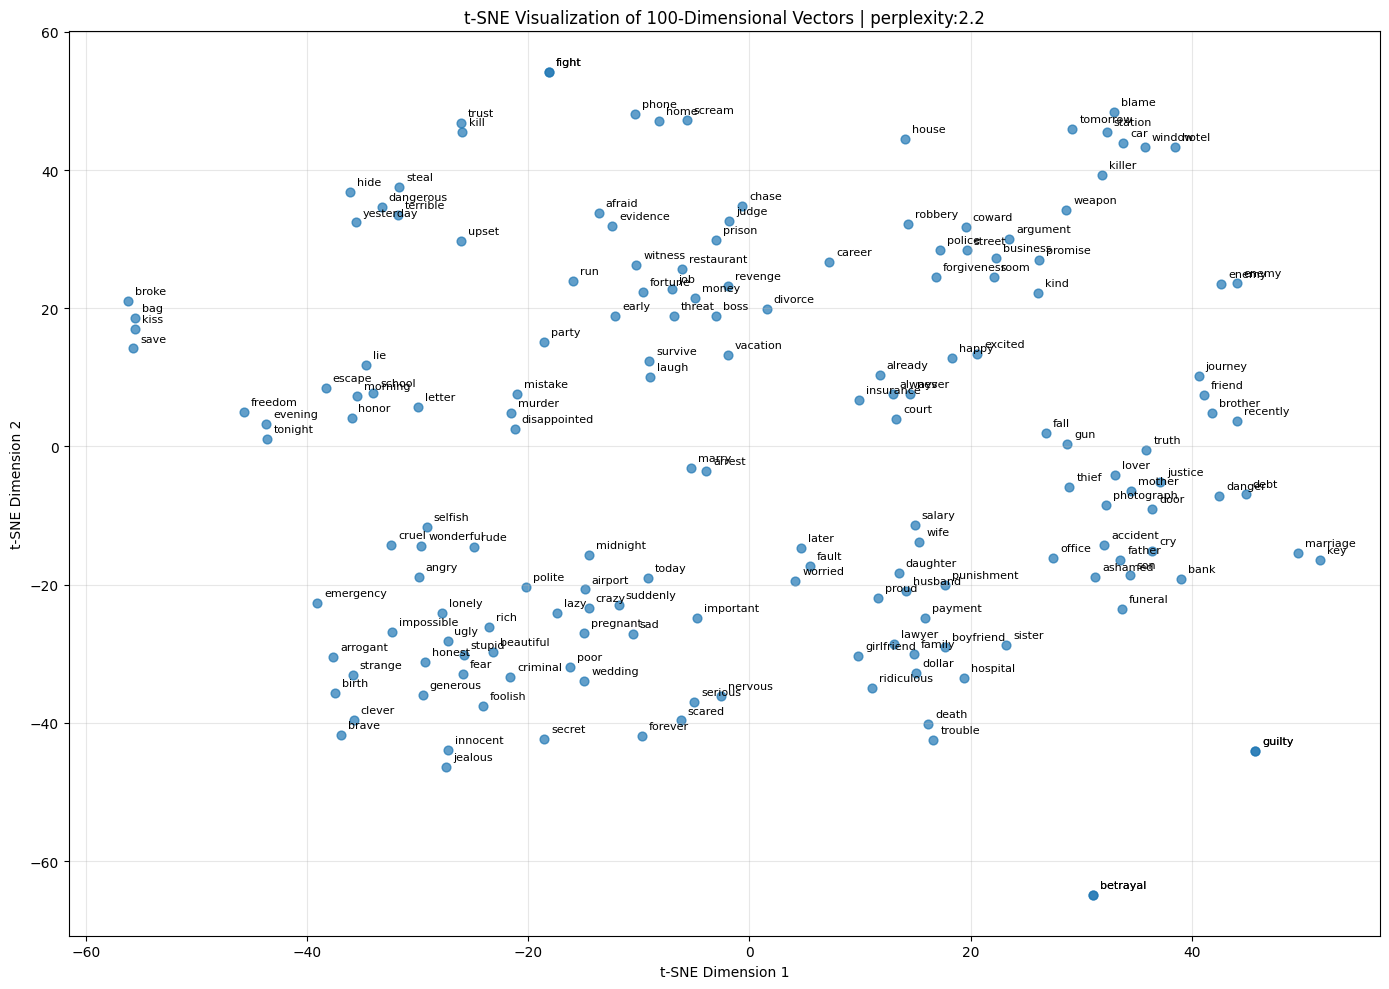

In [18]:
names = vocab_array[token_ids.tolist()]

# Apply t-SNE to reduce 100 dimensions to 2
perplexity = 2.2
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=42,
    init="pca",  #provides intitial position to tsne
    learning_rate="auto"
)

vectors_2d = tsne.fit_transform(vectors)

# Visualize the results
plt.figure(figsize=(14, 10))

plt.scatter(
    vectors_2d[:, 0],
    vectors_2d[:, 1],
    s=40,
    alpha=0.7
)

# Annotate each point with its name
for i, name in enumerate(names):
    plt.annotate(
        name,
        (vectors_2d[i, 0], vectors_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(f"t-SNE Visualization of 100-Dimensional Vectors | perplexity:{perplexity}")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

LSTM's embedding layer learns meaningfull representations from next-word prediction objective.